# Q-Learning on FrozenLake: Slippery vs. Normal Ice

Two tabular **Q-learning** agents learn the same 8×8 FrozenLake map:

- **Agent 1** trains on **slippery** ice, where each move goes the intended way only 1 time in 3.
- **Agent 2** trains on **normal** ice, where every move goes where it is told.

Both agents use the same algorithm and the same hyperparameters, so the ice is the only difference. Afterwards, each agent is tested on **both** kinds of ice.

**Author:** Ebrahim Shir jazi

*Built on Unit 2 of the [Hugging Face Deep RL Course](https://huggingface.co/learn/deep-rl-course/unit2/introduction) (Apache-2.0 license).*

## 1. Setup

Everything runs on a normal CPU runtime. No GPU is needed, because a Q-table is just a small NumPy array.

In [38]:
!pip install gymnasium pygame imageio imageio_ffmpeg

!sudo apt-get update
!sudo apt-get install -y python3-opengl
!apt install ffmpeg xvfb
!pip3 install pyvirtualdisplay

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:3 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:5 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:6 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:8 http://security.ubuntu.com/ubuntu noble-security InRelease
Fetched 3,917 B in 46s (84 B/s)
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
python3-opengl is already the newest version (3.1.7+dfsg-1).
0 upgraded, 0 newly installed, 0 to remove and 29 not upgraded.
Rea

The next cell will force the **runtime to crash, so you'll need to connect again and run the code starting from here**. Thanks to this trick, **we will be able to run our virtual screen.**

In [ ]:
import os
os.kill(os.getpid(), 9)

In [1]:
import numpy as np
import gymnasium as gym
import random
import imageio
import os
import tqdm
import pandas as pd
import matplotlib.pyplot as plt
import pickle

from gymnasium.envs.toy_text.frozen_lake import generate_random_map
from tqdm.notebook import tqdm
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Rectangle
from base64 import b64encode
from IPython.display import HTML, display

## 2. The environment

FrozenLake is a grid of frozen tiles (`F`), holes (`H`), a start (`S`) and a goal (`G`). The agent gets a reward of **1** for reaching the goal and **0** otherwise. An episode ends when the agent reaches the goal, falls into a hole, or has taken 100 steps.

- **State:** the tile the agent stands on, numbered 0–63 row by row.
- **Actions:** 0 = Left, 1 = Down, 2 = Right, 3 = Up. Walking into a wall leaves the agent where it is.

Both environments use the same map; only `is_slippery` differs.

_____OBSERVATION SPACE_____ 

Observation Space Discrete(64)
Sample observation 6

 _____ACTION SPACE_____ 

Action Space Shape 4
Action Space Sample 0 

There are  64  possible states
There are  4  possible actions



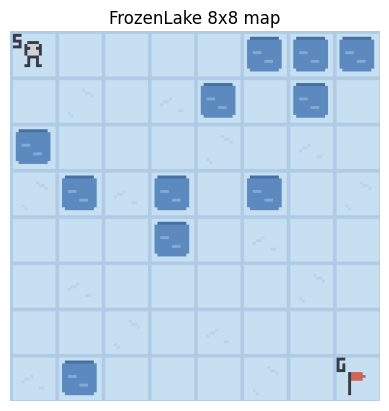

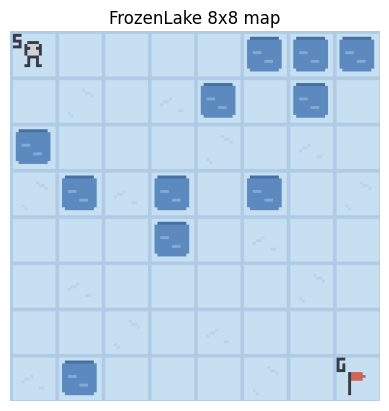

In [32]:
random_map = generate_random_map(size=8)  # a new random 8x8 map every run

env_normal = gym.make("FrozenLake-v1", desc=random_map, is_slippery=False, render_mode="rgb_array")
env_slippery = gym.make("FrozenLake-v1", desc=random_map, is_slippery=True, render_mode="rgb_array")


print("_____OBSERVATION SPACE_____ \n")
print("Observation Space", env_normal.observation_space)
print("Sample observation", env_normal.observation_space.sample(),)

print("\n _____ACTION SPACE_____ \n")
print("Action Space Shape", env_normal.action_space.n)
print("Action Space Sample", env_normal.action_space.sample(),"\n")  # Take a random action


state_space = env_normal.observation_space.n
print("There are ", state_space, " possible states")
action_space = env_normal.action_space.n
print("There are ", action_space, " possible actions\n")


env_normal.reset()
plt.imshow(env_normal.render())
plt.axis("off")
plt.title("FrozenLake 8x8 map")
plt.show()

env_slippery.reset()
plt.imshow(env_slippery.render())
plt.axis("off")
plt.title("FrozenLake 8x8 map")
plt.show()

## 3. Q-learning

The agent keeps a **Q-table** with one row per state and one column per action. Each entry estimates how much future reward an action brings from that state. After every step, the entry for the action just taken moves a little toward the **TD target**:

$$Q(s,a) \leftarrow Q(s,a) + \alpha \big[\, r + \gamma \max_{a'} Q(s',a') - Q(s,a) \,\big]$$

- **α (learning rate)** sets how big each update is.
- **γ (discount)** sets how much future rewards count.
- During training the agent acts **ε-greedily**: with probability ε it explores with a random action, otherwise it takes the best known action. ε starts at 1 and decays over the episodes.
- The update always uses the *best* next action (the max), while the agent itself acts ε-greedily. This is what makes Q-learning **off-policy**.
- **Ties are broken at random.** Before learning, every row of the Q-table is all zeros. `np.argmax` would then always pick action 0 (Left), so the agent keeps walking into the wall at the start. On normal ice this can stop it from ever finding the goal: across 16 training runs with different seeds, the normal-ice agent learned nothing in 10 runs with `np.argmax`, and learned the task in all 16 with random tie-breaking.

In [33]:
def initialize_q_table(state_space, action_space):
  Qtable = np.zeros((state_space, action_space))
  return Qtable

Qtable_normal = initialize_q_table(state_space, action_space)
Qtable_slippery = initialize_q_table(state_space, action_space)

def print_q_table(Qtable):
  print(Qtable[:5])    # first 5 rows
  print(" ...")
  print(Qtable[-1:])   # last row

print("Initial Q-table for normal environment:")
print_q_table(Qtable_normal)
print("\nInitial Q-table for slippery environment:")
print_q_table(Qtable_slippery)

Initial Q-table for normal environment:
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
 ...
[[0. 0. 0. 0.]]

Initial Q-table for slippery environment:
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
 ...
[[0. 0. 0. 0.]]


## 4. Policies

we have two policies since Q-Learning is an **off-policy** algorithm. This means we're using a **different policy for acting and updating the value function**.

- Epsilon-greedy policy (acting policy)
- Greedy-policy (updating policy)

The greedy policy will also be the final policy we'll have when the Q-learning agent completes training. The greedy policy is used to select an action using the Q-table.

In [34]:
def greedy_policy(Qtable, state):
  # Exploitation: take the action with the highest state, action value
  action = np.argmax(Qtable[state][:])

  return action

Epsilon-greedy is the training policy that handles the exploration/exploitation trade-off.

The idea with epsilon-greedy:

- With *probability 1 - ɛ* : **we do exploitation** (i.e. our agent selects the action with the highest state-action pair value).

- With *probability ɛ*: we do **exploration** (trying a random action).

As the training continues, we progressively **reduce the epsilon value since we will need less and less exploration and more exploitation.**

In [18]:
def epsilon_greedy_policy(Qtable, state, epsilon, env):

  random_num = random.uniform(0,1)              # Randomly generate a number between 0 and 1

  if random_num > epsilon:                      # if random_num > greater than epsilon --> exploitation
    action = greedy_policy(Qtable, state)

  else:                                         # else --> exploration
    action = env.action_space.sample()

  return action

## 5. Training

Both agents use the same hyperparameters:

| Setting | Value | Why |
|---|---|---|
| Episodes | 50,000 | On a big slippery map, reaching the goal by chance is rare, so the agent needs many tries. |
| Learning rate α | 0.1 | On slippery ice the same move gives different results; a small α averages them. |
| Discount γ | 0.99 | The path is long (at least 14 steps), so a far-away reward must not fade too much. |
| ε decay rate | 0.0001 | A slow decay keeps the agent exploring for longer. |
| Max steps | 99 | Steps per episode. |

Training both agents takes a minute or two on Colab's CPU.

In [35]:
# Training parameters
n_training_episodes = 50000  # Total training episodes
learning_rate = 0.1          # Learning rate

# Evaluation parameters
n_eval_episodes = 1000       # Total number of test episodes

# Environment parameters
env_id = "FrozenLake-v1"     # Name of the environment
max_steps = 99               # Max steps per episode
gamma = 0.99                 # Discounting rate
eval_seed = []               # The evaluation seed of the environment

# Exploration parameters
max_epsilon = 1.0            # Exploration probability at start
min_epsilon = 0.05           # Minimum exploration probability
decay_rate = 0.0001          # Exponential decay rate for exploration prob

In [36]:
def train(n_training_episodes, min_epsilon, max_epsilon, decay_rate, env, max_steps, Qtable):
  # Tiles where an episode can start: Start (S) or Frozen (F), not Hole (H) or Goal (G)
  tiles = env.unwrapped.desc.flatten()
  safe_tiles = [state for state in range(len(tiles)) if tiles[state] in b"SF"]

  for episode in tqdm(range(n_training_episodes)):
    # Reduce epsilon (because we need less and less exploration)
    epsilon = min_epsilon + (max_epsilon - min_epsilon)*np.exp(-decay_rate*episode)
    # Reset the environment
    state, info = env.reset()
    # Start on a random safe tile, so the agent learns every tile (no "?" later)
    state = random.choice(safe_tiles)
    env.unwrapped.s = state
    step = 0
    terminated = False
    truncated = False

    # repeat
    for step in range(max_steps):
      # Choose the action At using epsilon greedy policy
      action = epsilon_greedy_policy(Qtable, state, epsilon, env)

      # Take action At and observe Rt+1 and St+1
      # Take the action (a) and observe the outcome state(s') and reward (r)
      new_state, reward, terminated, truncated, info = env.step(action)

      # Update Q(s,a):= Q(s,a) + lr [R(s,a) + gamma * max Q(s',a') - Q(s,a)]
      Qtable[state][action] = Qtable[state][action] + learning_rate * (reward + gamma * np.max(Qtable[new_state]) - Qtable[state][action])

      # If terminated or truncated finish the episode
      if terminated or truncated:
        break

      # Our next state is the new state
      state = new_state
  return Qtable

In [37]:
Qtable_normal = train(n_training_episodes, min_epsilon, max_epsilon, decay_rate, env_normal, max_steps, Qtable_normal)
Qtable_slippery = train(n_training_episodes, min_epsilon, max_epsilon, decay_rate, env_slippery, max_steps, Qtable_slippery)

  0%|          | 0/50000 [00:00<?, ?it/s]

  0%|          | 0/50000 [00:00<?, ?it/s]

## 6. Evaluation

Each agent now plays 1,000 games on related ice with its **greedy** policy (no exploration). The reward is 1 for a win and 0 otherwise, so the mean reward is the **win rate**.

The last row is a reference: the best win rate *any* agent could reach within 99 steps. FrozenLake's rules are known (`env.unwrapped.P`), so dynamic programming can compute it exactly.

In [38]:
print("Q-table for normal ice after training:")
print_q_table(Qtable_normal)
print("\nQ-table for slippery ice after training:")
print_q_table(Qtable_slippery)

Q-table for normal ice after training:
[[0.86871569 0.87752102 0.87748813 0.86871278]
 [0.86874142 0.88638487 0.8863808  0.8775188 ]
 [0.87752074 0.89533825 0.89533611 0.8863837 ]
 [0.88638402 0.90438208 0.88638369 0.89533769]
 [0.89533825 0.         0.         0.88600084]]
 ...
[[0. 0. 0. 0.]]

Q-table for slippery ice after training:
[[0.18750181 0.18816076 0.21512663 0.18964866]
 [0.19592948 0.19121762 0.23087716 0.20112576]
 [0.21889876 0.21992937 0.24546936 0.21934687]
 [0.24712097 0.16498514 0.17452031 0.16354454]
 [0.04611601 0.09400271 0.03764317 0.06142044]]
 ...
[[0. 0. 0. 0.]]


In [39]:
def evaluate_agent(env, max_steps, n_eval_episodes, Q, seed):
  """
  Evaluate the agent for ``n_eval_episodes`` episodes and returns average reward and std of reward.
  :param env: The evaluation environment
  :param max_steps: Maximum number of steps per episode
  :param n_eval_episodes: Number of episode to evaluate the agent
  :param Q: The Q-table
  :param seed: The evaluation seed array (for taxi-v3)
  """
  episode_rewards = []
  for episode in tqdm(range(n_eval_episodes)):
    if seed:
      state, info = env.reset(seed=seed[episode])
    else:
      state, info = env.reset()
    step = 0
    truncated = False
    terminated = False
    total_rewards_ep = 0

    for step in range(max_steps):
      # Take the action (index) that have the maximum expected future reward given that state
      action = greedy_policy(Q, state)
      new_state, reward, terminated, truncated, info = env.step(action)
      total_rewards_ep += reward

      if terminated or truncated:
        break
      state = new_state
    episode_rewards.append(total_rewards_ep)
  mean_reward = np.mean(episode_rewards)
  std_reward = np.std(episode_rewards)

  return mean_reward, std_reward

In [41]:
# Evaluate our agents, each on both kinds of ice
mean_reward, std_reward = evaluate_agent(env_normal, max_steps, n_eval_episodes, Qtable_normal, eval_seed)
print(f"Normal agent on normal ice:     Mean_reward={mean_reward:.2f} +/- {std_reward:.2f}","\n")

mean_reward, std_reward = evaluate_agent(env_slippery, max_steps, n_eval_episodes, Qtable_slippery, eval_seed)
print(f"Slippery agent on slippery ice: Mean_reward={mean_reward:.2f} +/- {std_reward:.2f}")

  0%|          | 0/1000 [00:00<?, ?it/s]

Normal agent on normal ice:     Mean_reward=1.00 +/- 0.00 



  0%|          | 0/1000 [00:00<?, ?it/s]

Slippery agent on slippery ice: Mean_reward=0.34 +/- 0.48


## 7. What each agent learned

Each grid shows one agent's Q-table on the map. The arrow is the action the agent picks on that tile, and the color is the tile's value (its best Q-value): darker means the agent expects to reach the goal more surely or sooner. A `?` marks a tile the agent never learned anything about.

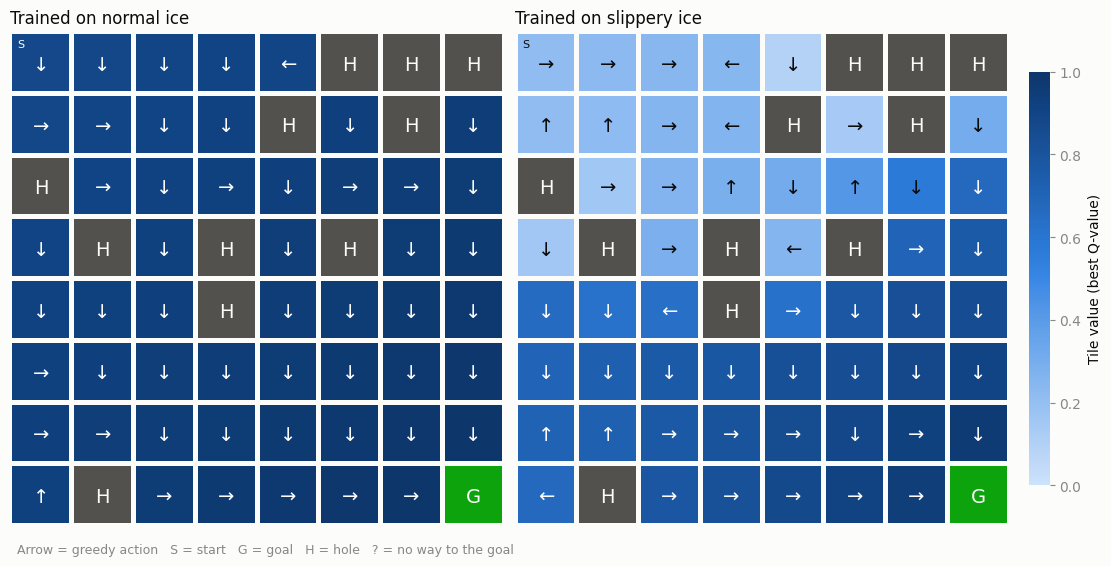

In [42]:
VALUE_RAMP = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7", "#3987e5",
              "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
VALUE_CMAP = LinearSegmentedColormap.from_list("value", VALUE_RAMP)
SURFACE, INK, MUTED, HOLE, GOAL = "#fcfcfb", "#0b0b0b", "#898781", "#52514e", "#0ca30c"
ARROWS = "←↓→↑"  # actions 0, 1, 2, 3


def plot_policy(ax, Q, env, title):
    game_map = env.unwrapped.desc.astype(str)  # the map as letters: S, F, H, G
    n = game_map.shape[0]
    for r in range(n):
        for c in range(n):
            s, tile = r * n + c, game_map[r, c]
            if tile == "H":
                fill, label, ink = HOLE, "H", SURFACE
            elif tile == "G":
                fill, label, ink = GOAL, "G", SURFACE
            else:
                value = Q[s].max()
                fill = VALUE_CMAP(value)
                label = ARROWS[np.argmax(Q[s])] if Q[s].any() else "?"
                ink = SURFACE if value > 0.6 else INK
            ax.add_patch(Rectangle((c + 0.04, r + 0.04), 0.92, 0.92, facecolor=fill, edgecolor="none"))
            ax.text(c + 0.5, r + 0.53, label, ha="center", va="center", fontsize=14, color=ink)
            if tile == "S":
                ax.text(c + 0.12, r + 0.2, "S", ha="left", va="center", fontsize=8, color=ink)
    ax.set_xlim(0, n)
    ax.set_ylim(n, 0)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title, loc="left", fontsize=12, color=INK)


fig, axes = plt.subplots(1, 2, figsize=(11, 5.6), facecolor=SURFACE, layout="constrained")
plot_policy(axes[0], Qtable_normal, env_normal, "Trained on normal ice")
plot_policy(axes[1], Qtable_slippery, env_slippery, "Trained on slippery ice")
bar = fig.colorbar(ScalarMappable(norm=Normalize(0, 1), cmap=VALUE_CMAP), ax=axes, shrink=0.75, pad=0.02)
bar.set_label("Tile value (best Q-value)", color=INK)
bar.outline.set_visible(False)
bar.ax.tick_params(colors=MUTED)
fig.text(0.01, 0.01, "Arrow = greedy action   S = start   G = goal   H = hole   ? = no way to the goal",
         fontsize=9, color=MUTED)
plt.show()

On slippery ice, an arrow shows which button the agent presses, not where it will move. When you press a direction, you move that way only 1 time in 3. The other times you slide to one of the two sides, never backwards. So the agent picks the button whose possible slides can’t drop it into a hole.

### 8. Replays

One game per agent, each on its own kind of ice. On slippery ice every game turns out differently, so re-run the cell to watch another one.

In [43]:
def record_video(env, Qtable, out_directory, fps=1):
  images = []
  terminated = False
  truncated = False
  state, info = env.reset(seed=random.randint(0,500))
  img = env.render()
  images.append(img)
  while not (terminated or truncated):
    # Take the action (index) that have the maximum expected future reward given that state
    action = np.argmax(Qtable[state][:])
    state, reward, terminated, truncated, info = env.step(action)  # We directly put next_state = state for recording logic
    img = env.render()
    images.append(img)
  imageio.mimsave(out_directory, [np.array(img) for i, img in enumerate(images)], fps=fps)
  return reward == 1  # True if the agent reached the goal


def show_video(path, width=360):
  data = b64encode(open(path, "rb").read()).decode()
  return HTML(f'<video width="{width}" controls loop autoplay muted>'
              f'<source src="data:video/mp4;base64,{data}" type="video/mp4"></video>')

In [44]:
# Normal ice: the agent takes the same path every game, so one game is enough
won = record_video(env_normal, Qtable_normal, "replay_normal.mp4", fps=4)
print("Normal agent on normal ice:", "reached the goal" if won else "did not reach the goal")
display(show_video("replay_normal.mp4"))

# Slippery ice: every game is different, so play until one reaches the goal (at most 100 games)
for game in range(1, 101):
  won = record_video(env_slippery, Qtable_slippery, "replay_slippery.mp4", fps=4)
  if won:
    break
print(f"Slippery agent on slippery ice: {'reached the goal' if won else 'did not reach the goal'} in game {game}")
display(show_video("replay_slippery.mp4"))

Normal agent on normal ice: reached the goal


Slippery agent on slippery ice: reached the goal in game 1


## Takeaways

- **The slippery-ice agent wins roughly 6 games in 10 (slight different according to each random map), close to the best possible (about 64%).** Slipping, holes next to the path and the 99-step limit make 100% impossible on slippery ice.
- **The normal-ice agent wins every game on normal ice,** taking a shortest path (14 steps).
- **Each agent fails on the other's ice.** The slippery-ice agent learned moves that only work with sliding, such as pressing against a wall to slide sideways. On normal ice those moves just bump the wall, so it can get stuck. The normal-ice agent's shortest path runs right next to holes, so on slippery ice it almost always slides into one.
- **A Q-table only fits the world it was trained in.** Handling new maps or new physics needs an agent trained on many variations, usually with a neural network instead of a table (Deep Q-Learning).

## Next steps

- Compare with SARSA, the on-policy version of this algorithm, on slippery ice.
- Train one agent on a mix of slippery and normal episodes.